In [1]:
import os, sys
from pathlib import Path

# Localizar a raiz do projeto (pasta que contém "src/") para poder importar os módulos auxiliares
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
print("Raiz do projeto:", PROJECT_ROOT)

Raiz do projeto: /mnt/attach/outputs/IA3_Projeto-Creditcard


# 1. Business and Data Understanding (Metodologia CRISP-ML)

## 1.1. Enquadramento e Objetivos
Dataset **Credit Card Fraud Detection** (Kaggle / ULB): transações de cartões europeus em setembro de 2013, durante 2 dias.
O objetivo de negócio é **detetar transações fraudulentas** para as bloquear/rever antes de causarem prejuízo.

Abordagem desta fase:
- **Machine Learning Canvas** e **Contrato de dados**.
- **Resumo estrutural** e **qualidade** (nulos e duplicados).
- **Análise univariada**: estatística descritiva, *Skewness* e *Kurtosis*.
- **Análise bivariada**: variável alvo `Class` (desequilíbrio de classes).
- **Análise multivariada**: correlação de **Pearson** vs **Spearman**.
- **Componente temporal**: fraudes por hora do dia.

## 1.2. Machine Learning Canvas

| Bloco | Descrição |
|---|---|
| **Value propositions** | Detetar fraude em tempo útil, minimizando prejuízo financeiro e fricção para clientes legítimos. |
| **Decisions** | Bloquear / pedir confirmação / aprovar cada transação. |
| **ML task** | Classificação binária (`Class`: 0 = legítima, 1 = fraude). |
| **Data sources** | `creditcard.csv` (284 807 transações, Kaggle - ULB Machine Learning Group). |
| **Collecting data** | Dataset público e estático; em produção, fluxo contínuo de transações. |
| **Features** | `V1..V28` (PCA, anonimizadas), `Amount`, `Time` → `Hour`, `Amount_log`. |
| **Making predictions** | Uma previsão por transação (online, baixa latência). |
| **Building models** | Re-treino periódico com os dados mais recentes (divisão temporal). |
| **Evaluation / KPIs** | PR-AUC, Recall e Precision da classe fraude (accuracy é enganadora: 99.83% é a baseline "tudo legítimo"). |
| **Monitoring** | Deriva das features e da taxa de fraude; recall em fraudes confirmadas. |

## 1.3. Contrato de dados
Formato, nomes e tipos de atributos, unidades, frequência de amostragem e componente temporal (definidos em `src/config.py`).

In [2]:
import json
from src.config import DATA_CONTRACT
print(json.dumps(DATA_CONTRACT, indent=2, ensure_ascii=False))

{
  "formato": "CSV (separador ',', cabeçalho na 1ª linha, codificação UTF-8)",
  "granularidade": "1 linha = 1 transação de cartão de crédito",
  "componente_temporal": "Sim - 'Time' = segundos desde a 1ª transação (~48h, 2 dias de set/2013)",
  "frequencia_amostragem": "Irregular (evento: cada transação); sem frequência fixa",
  "unidades": {
    "Time": "segundos",
    "Amount": "euros (EUR)"
  },
  "colunas": {
    "Time": "int/float",
    "V1": "float",
    "V2": "float",
    "V3": "float",
    "V4": "float",
    "V5": "float",
    "V6": "float",
    "V7": "float",
    "V8": "float",
    "V9": "float",
    "V10": "float",
    "V11": "float",
    "V12": "float",
    "V13": "float",
    "V14": "float",
    "V15": "float",
    "V16": "float",
    "V17": "float",
    "V18": "float",
    "V19": "float",
    "V20": "float",
    "V21": "float",
    "V22": "float",
    "V23": "float",
    "V24": "float",
    "V25": "float",
    "V26": "float",
    "V27": "float",
    "V28": "float",
    "

## 1.4. Carregamento dos dados e validação do contrato

In [3]:
from src import eda_creditcard as eda
df = eda.carregar_dados()
eda.validar_contrato_dados(df)

[SUCESSO] 284807 registos | 31 colunas carregadas de '/mnt/attach/outputs/IA3_Projeto-Creditcard/data/raw/creditcard.csv'
Contrato de dados: CUMPRIDO


True

## 1.5. Inspeção da estrutura geral

In [4]:
eda.resumo_estrutura(df, nome='creditcard.csv')

1. RESUMO DA ESTRUTURA DOS DADOS: creditcard.csv
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.1412

## 1.6. Qualidade dos dados (nulos e duplicados)

In [5]:
relatorio_nulos = eda.analisar_qualidade_dados(df)

2. ANÁLISE DE QUALIDADE DOS DADOS (NULOS E DUPLICADOS)


Linhas duplicadas encontradas: 1081 (0.38%)
Não foram encontrados valores nulos.


## 1.7. Análise univariada e estatística avançada (Skewness e Kurtosis)
`Amount` é extremamente assimétrica e de cauda pesada; `V1..V28` têm média ≈ 0 (PCA).

In [6]:
resumo = eda.estatisticas_descritivas_completas(df)

3. ESTATÍSTICAS DESCRITIVAS E EDA AVANÇADA


             mean        std      min        50%         max  skewness  \
Time    94813.860  47488.146    0.000  84692.000  172792.000    -0.036   
V1          0.000      1.959  -56.408      0.018       2.455    -3.281   
V2          0.000      1.651  -72.716      0.065      22.058    -4.625   
V3         -0.000      1.516  -48.326      0.180       9.383    -2.240   
V4          0.000      1.416   -5.683     -0.020      16.875     0.676   
V5          0.000      1.380 -113.743     -0.054      34.802    -2.426   
V6          0.000      1.332  -26.161     -0.274      73.302     1.827   
V7         -0.000      1.237  -43.557      0.040     120.589     2.554   
V8          0.000      1.194  -73.217      0.022      20.007    -8.522   
V9         -0.000      1.099  -13.434     -0.051      15.595     0.555   
V10         0.000      1.089  -24.588     -0.093      23.745     1.187   
V11         0.000      1.021   -4.797     -0.033      12.019     0.357   
V12        -0.000      0.999  -18.684 

## 1.8. Análise da variável alvo (`Class`)
Desequilíbrio extremo → implica métricas apropriadas e tratamento na modelação.

4. ANÁLISE DA VARIÁVEL ALVO: 'Class' (0 = legítima, 1 = fraude)
       contagem        %
Class                   
0        284315  99.8273
1           492   0.1727
Rácio de desequilíbrio: 1 fraude para cada 578 legítimas


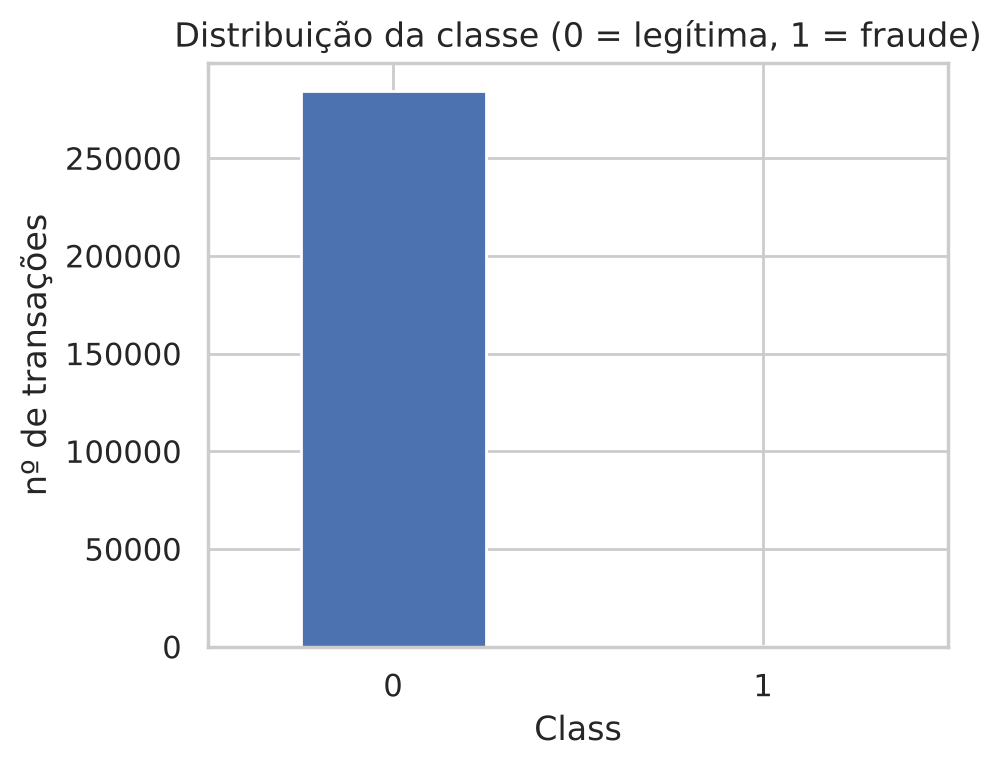

In [7]:
contagem = eda.analisar_variavel_alvo(df)

## 1.9. Análise multivariada: Pearson vs Spearman

5. ANÁLISE MULTIVARIADA: CORRELAÇÃO (PEARSON VS SPEARMAN)



Top 10 features mais correlacionadas com a classe (Pearson):
     pearson  spearman  abs_pearson
V17   -0.326    -0.047        0.326
V14   -0.303    -0.065        0.303
V12   -0.261    -0.064        0.261
V10   -0.217    -0.061        0.217
V16   -0.197    -0.050        0.197
V3    -0.193    -0.060        0.193
V7    -0.187    -0.045        0.187
V11    0.155     0.063        0.155
V4     0.133     0.062        0.133
V18   -0.111    -0.038        0.111


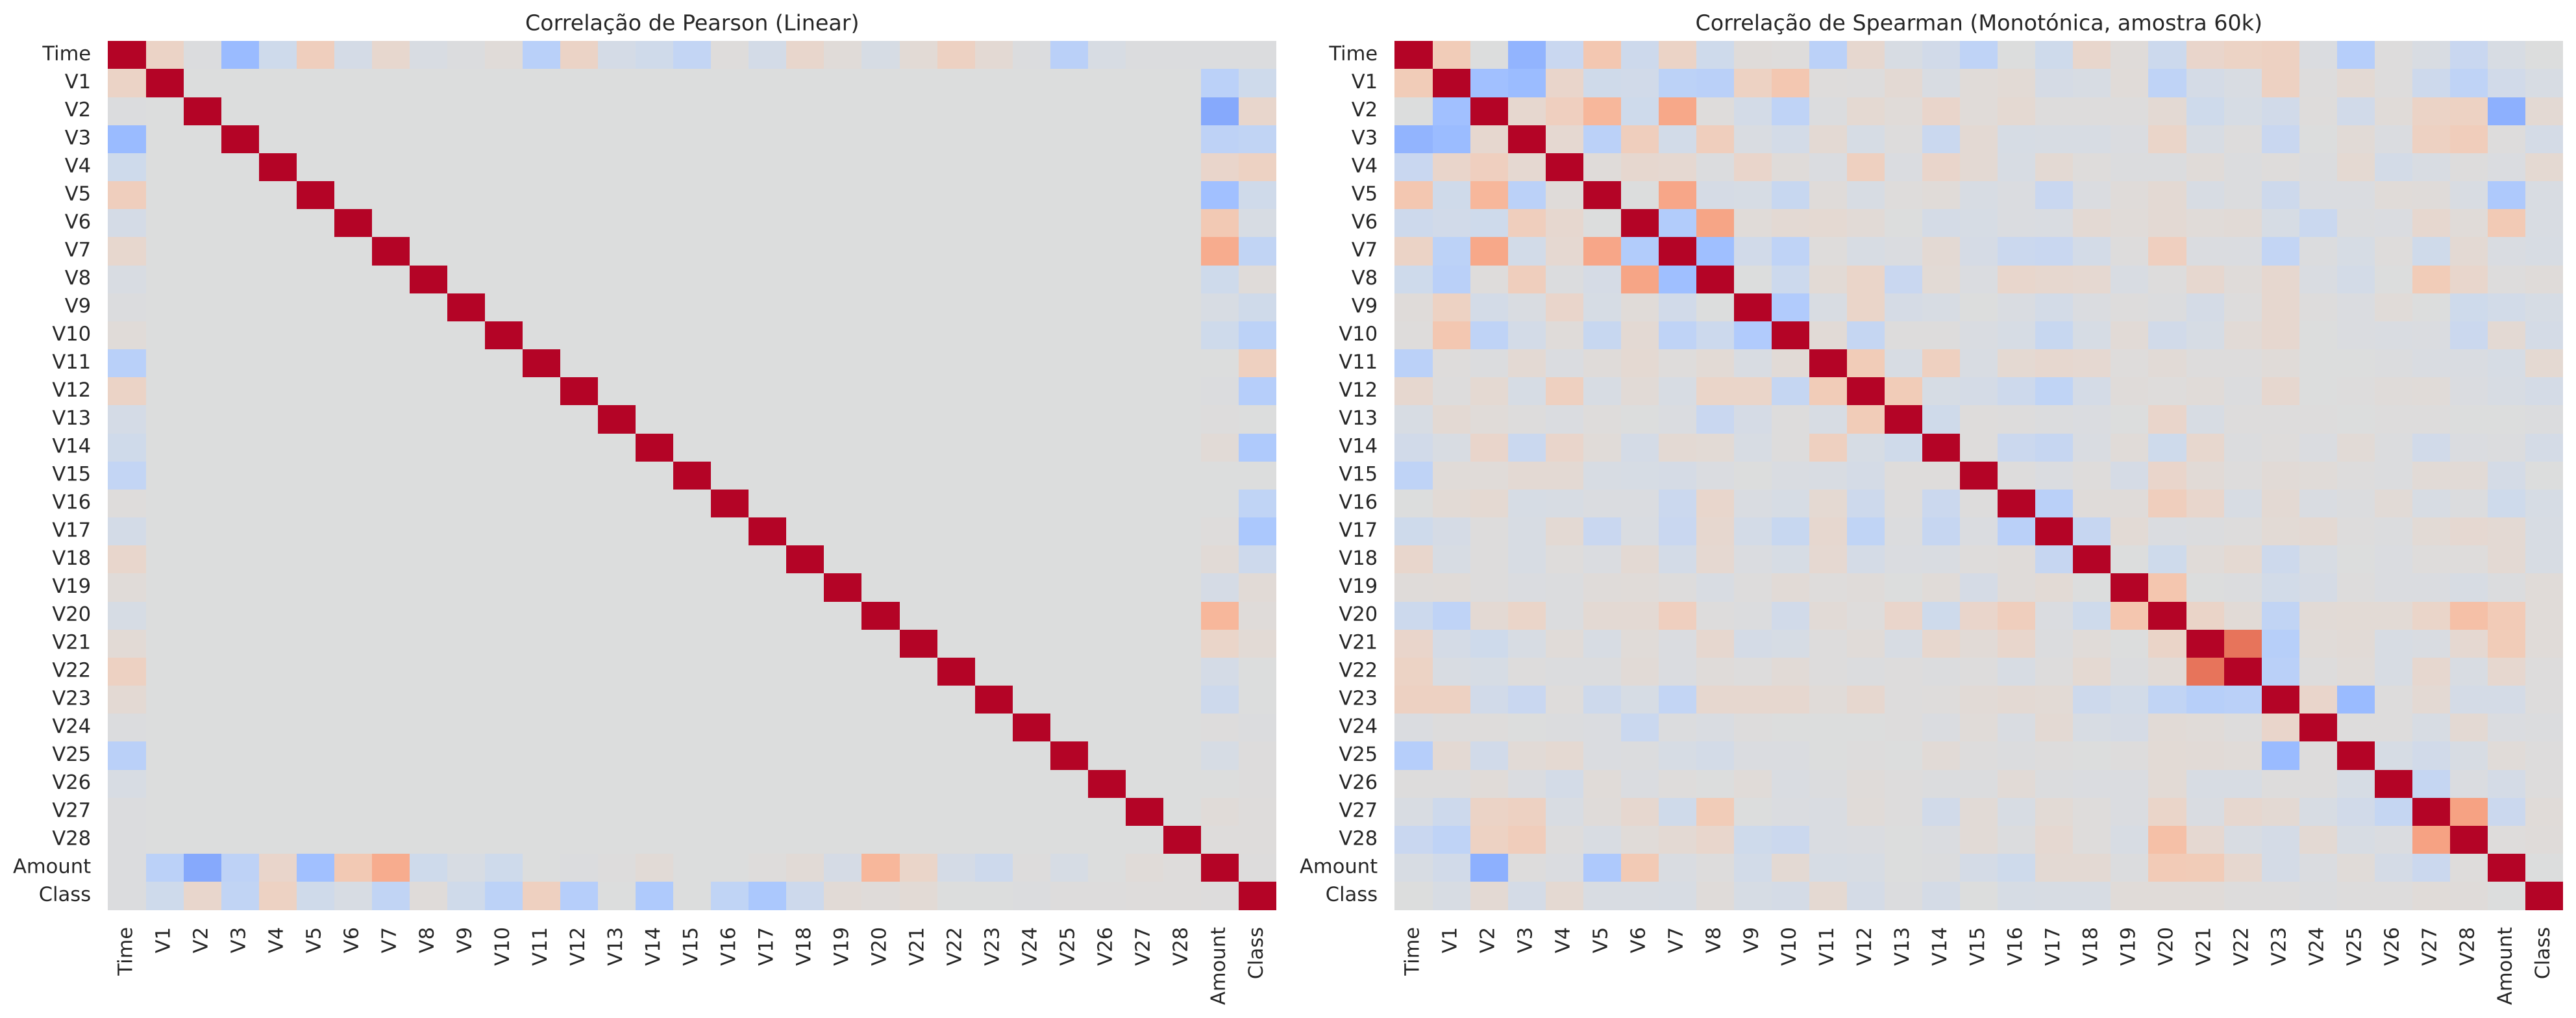

In [8]:
corr_alvo = eda.analisar_correlacoes(df)

## 1.10. Distribuição das features mais discriminativas por classe

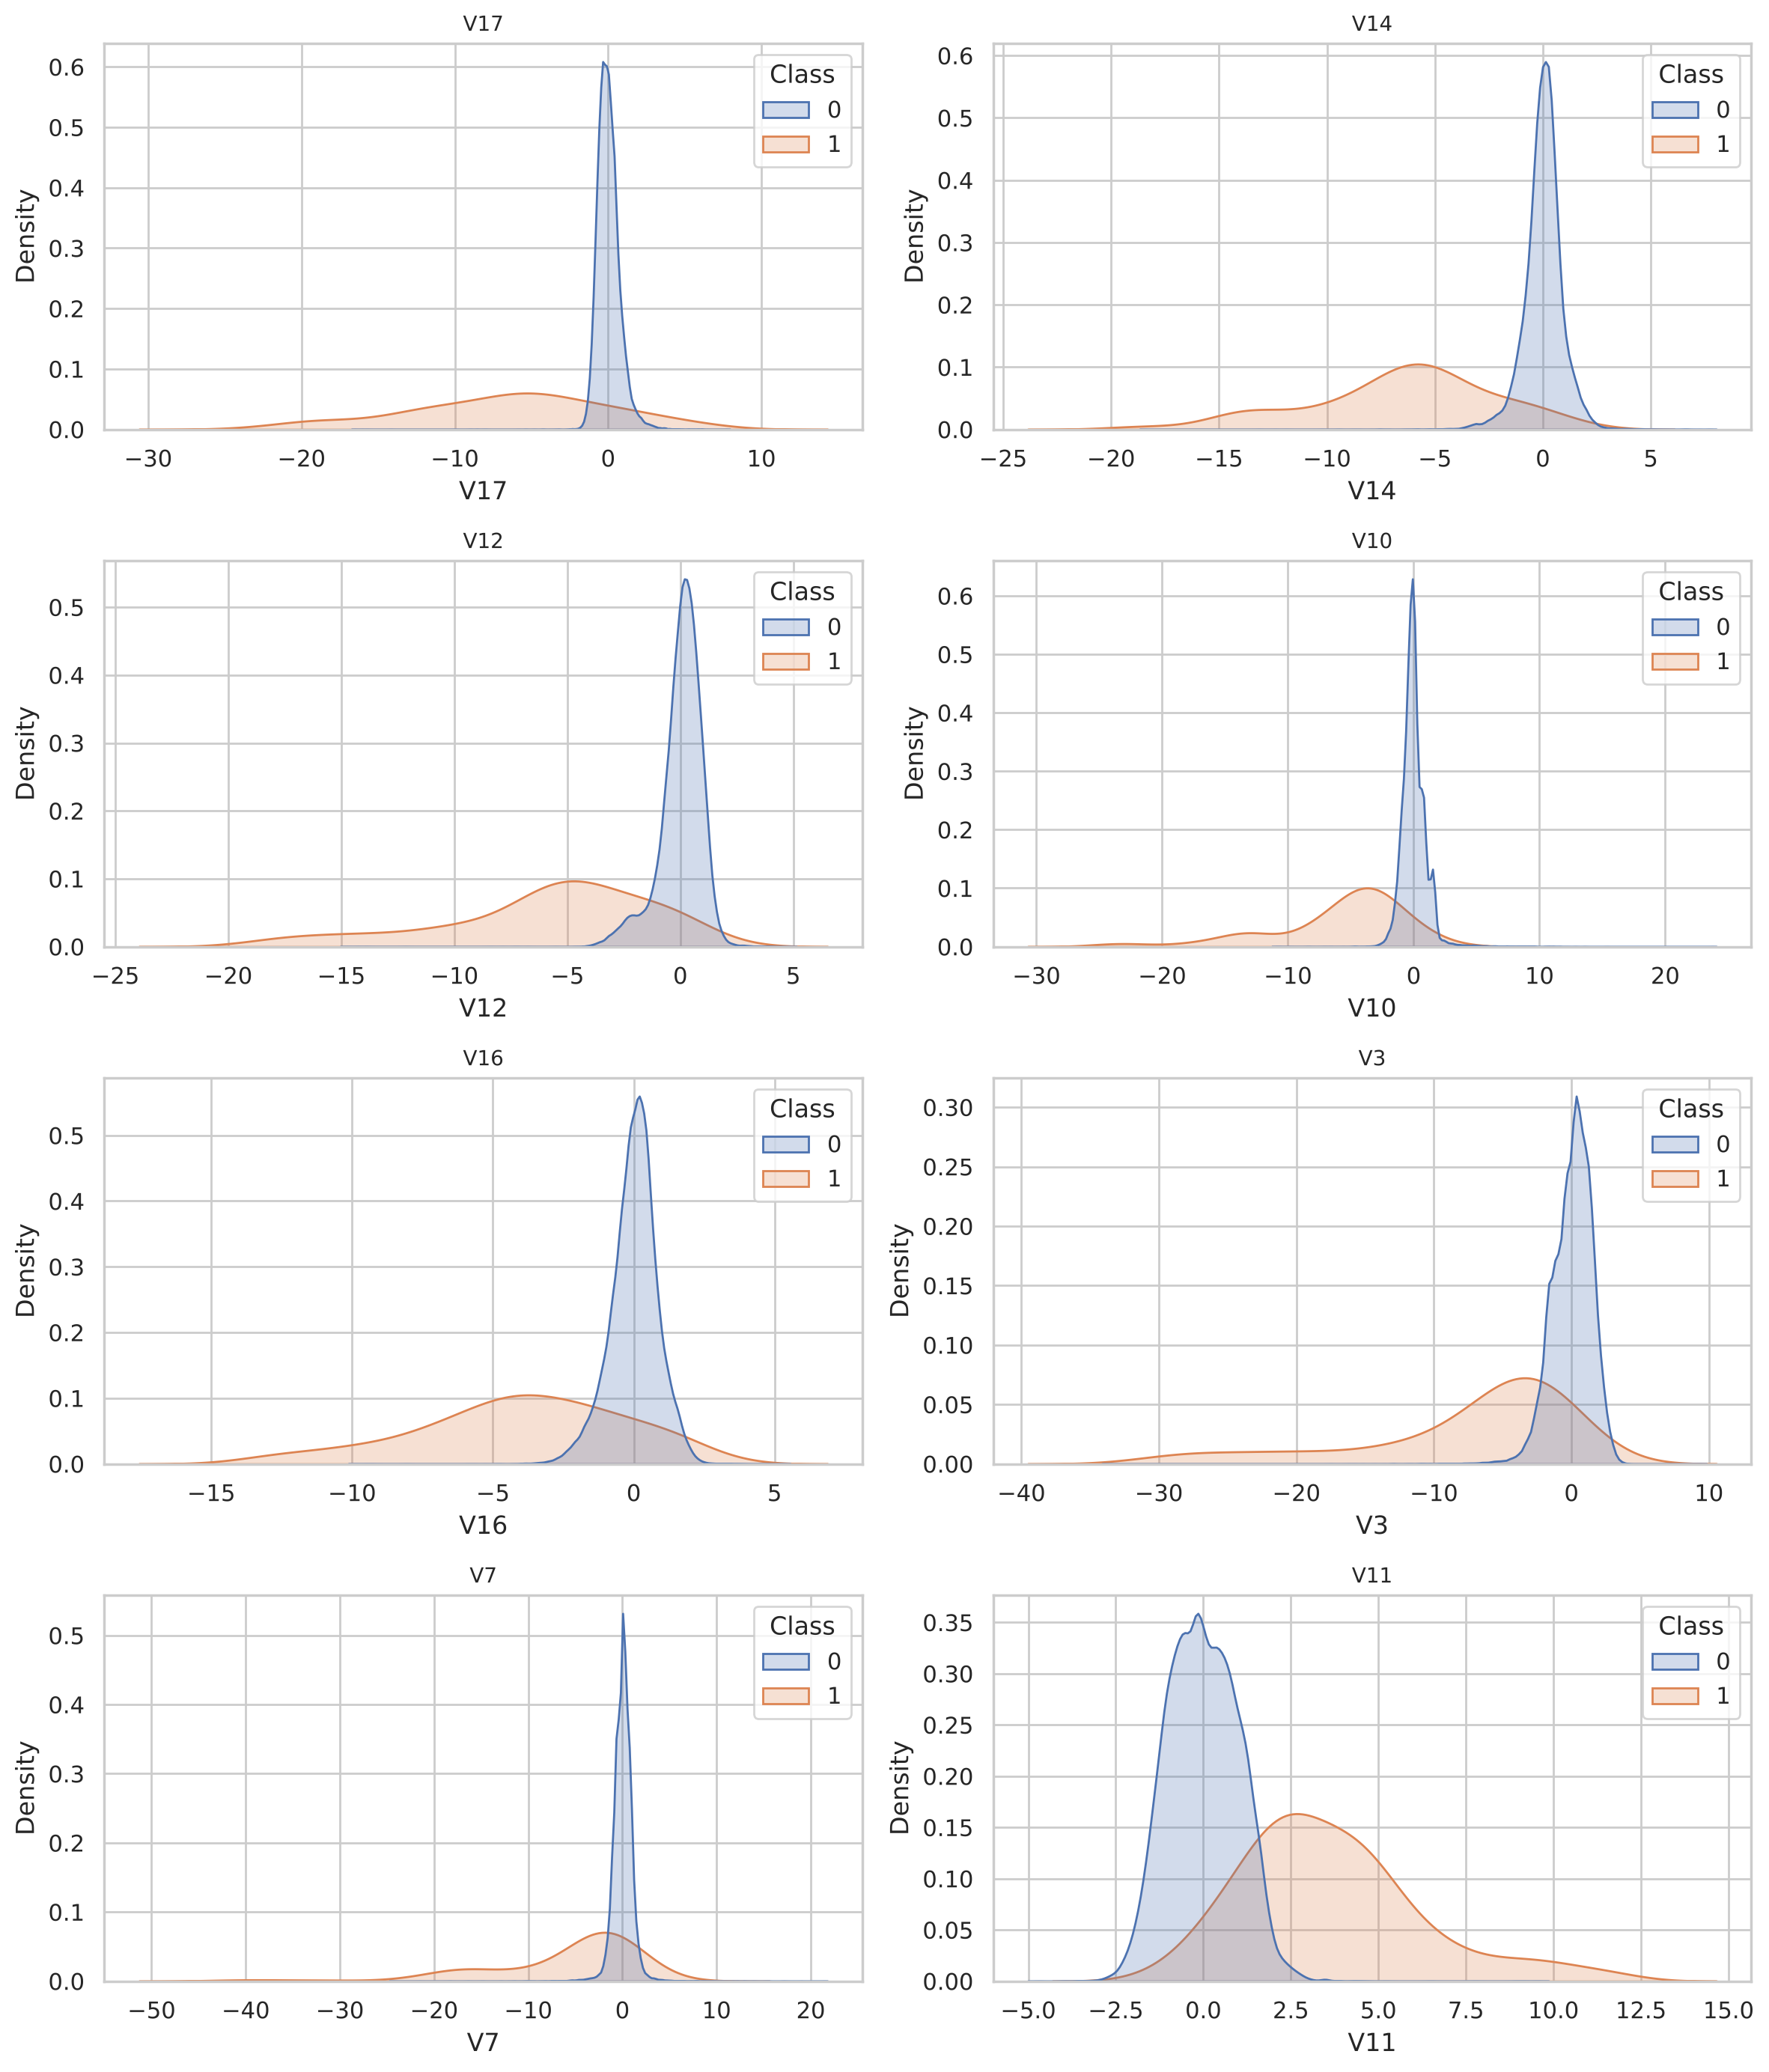

In [9]:
top_features = eda.distribuicoes_por_classe(df)

## 1.11. Componente temporal
Taxa de fraude por hora do dia (a hora é derivada de `Time`).

In [10]:
por_hora = eda.analise_temporal(df)

      transacoes  fraudes  taxa_fraude
Hour                                  
0           7695        6       0.0008
1           4220       10       0.0024
2           3328       57       0.0171
3           3492       17       0.0049
4           2209       23       0.0104
5           2990       11       0.0037
6           4101        9       0.0022
7           7243       23       0.0032
8          10276        9       0.0009
9          15838       16       0.0010
10         16598        8       0.0005
11         16856       53       0.0031
12         15420       17       0.0011
13         15365       17       0.0011
14         16570       23       0.0014
15         16461       26       0.0016
16         16453       22       0.0013
17         16166       29       0.0018
18         17039       33       0.0019
19         15649       19       0.0012
20         16756       18       0.0011
21         17703       16       0.0009
22         15441        9       0.0006
23         10938       21

## 1.12. Conclusões e implicações para a Data Preparation
1. **Sem nulos**, mas **1081 duplicados** (≈0.38%) → remover.
2. **Desequilíbrio extremo (≈0.17% fraudes)** → `class_weight`/amostragem e métricas PR-AUC/Recall/F1 da fraude.
3. `V1..V28` já estão em escala PCA; `Amount` é muito assimétrico → `Amount_log` + StandardScaler.
4. `Time` é um contador em segundos → substituir por `Hour`; **divisão cronológica** (não aleatória) para evitar *data leakage*.
5. Features mais associadas à fraude: `V17`, `V14`, `V12`, `V10` (correlação negativa).